[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/03_hito3_metricas.ipynb)

# 03 · Hito 3: la corriente y sus tres métricas en los cuatro modelos

**Qué pide el enunciado.** Una sola figura con la corriente y sus tres métricas en los cuatro modelos, y una tabla
con $\Delta M_{\rm reflex} = M_B - M_A$, $\Delta M_{\rm direct} = M_C - M_A$, $\Delta M_{\rm full} = M_D - M_A$ y
$f_{\rm reflex} = |\Delta M_{\rm reflex}| / (|\Delta M_{\rm reflex}| + |\Delta M_{\rm direct}|)$.
También: las corrientes y las métricas a lo largo de la corriente para una corriente **corta**, una **larga** y
una de **dos vueltas** (resultados esperados del enunciado).

**El piso del modelo A.** Lo que se mide en A no viene de la LMC: viene del disco (que hace precesar los planos
orbitales que no son polares), de la dispersión de las estrellas liberadas y del propio método. Es el piso
contra el que se comparan B, C y D.

In [1]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Python 3.13.16
  numpy       2.2.6
  scipy       1.18.1
  astropy     8.0.2
  gala        1.12.0


  matplotlib  3.11.2
  pandas      3.1.0


  healpy      1.20.1
  galstreams  1.2.1
Salidas en: salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("03_hito3")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/03_hito3.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: salidas/03_hito3_20261027_204008


In [3]:
import time
from p3streams import potenciales as P, corrientes as Co, metricas as Me, figuras as F, catalogo as Ca
sis = P.integrar_sistema()
mods = P.modelos(sis)

def cuatro(polo, r_apo, m_prog, t_start, f=0.5, psi=0.0):
    x0, v0 = Co.condiciones_iniciales(polo, r_apo, f, psi)
    corr = {m: Co.generar(mods[m], x0, v0, m_prog=m_prog, t_inicio=-t_start) for m in "ABCD"}
    res, perf = {}, {}
    for m in "ABCD":
        res[m], perf[m] = Me.medir(corr[m], polo)
    return x0, corr, res, perf

def tabla(res, parte="todo"):
    filas = []
    for met, nombre in (("desalineamiento_deg", "PM misalignment (deg)"), ("tilt_polo_deg", "pole tilt (deg)"),
                        ("tilt_plano_deg", "plane tilt, SVD (deg)"), ("dispersion_polos_deg", "pole spread (deg)")):
        p = Me.perturbaciones(res, met, parte)
        filas.append([nombre, "%.2f" % res["A"][parte][met], "%+.2f" % p["dM_reflex"], "%+.2f" % p["dM_direct"],
                      "%+.2f" % p["dM_full"], "%.2f" % p["f_reflex"], Me.clase(p["f_reflex"])])
    cp = Me.cambio_polo(res, parte)
    filas.append(["pole change vs A (deg)", "0", "%.2f" % cp["B"], "%.2f" % cp["C"], "%.2f" % cp["D"],
                  "%.2f" % cp["f_reflex"], Me.clase(cp["f_reflex"])])
    return filas

COLS = ["metric", "M_A", "dM_reflex", "dM_direct", "dM_full", "f_reflex", "class"]
N0 = np.array([0.0, -1.0, 0.0])
t0 = time.time()
x0, CORR, RES, PERF = cuatro(N0, 100.0, 1e7, 4000.0)
print("Progenitor del hito 1: 4 modelos en %.0f s" % (time.time() - t0))
pd.DataFrame(tabla(RES), columns=COLS)

Progenitor del hito 1: 4 modelos en 12 s


,metric,M_A,dM_reflex,dM_direct,dM_full,f_reflex,class
0,PM misalignment (deg),0.82,+1.76,+2.32,+2.27,0.43,mixed
1,pole tilt (deg),0.02,+19.98,+5.03,+9.88,0.80,reflex
2,"plane tilt, SVD (deg)",0.02,+12.60,+3.30,+8.53,0.79,reflex
3,pole spread (deg),0.75,+1.48,+2.35,+2.05,0.39,torque
4,pole change vs A (deg),0,20.00,5.06,9.90,0.80,reflex


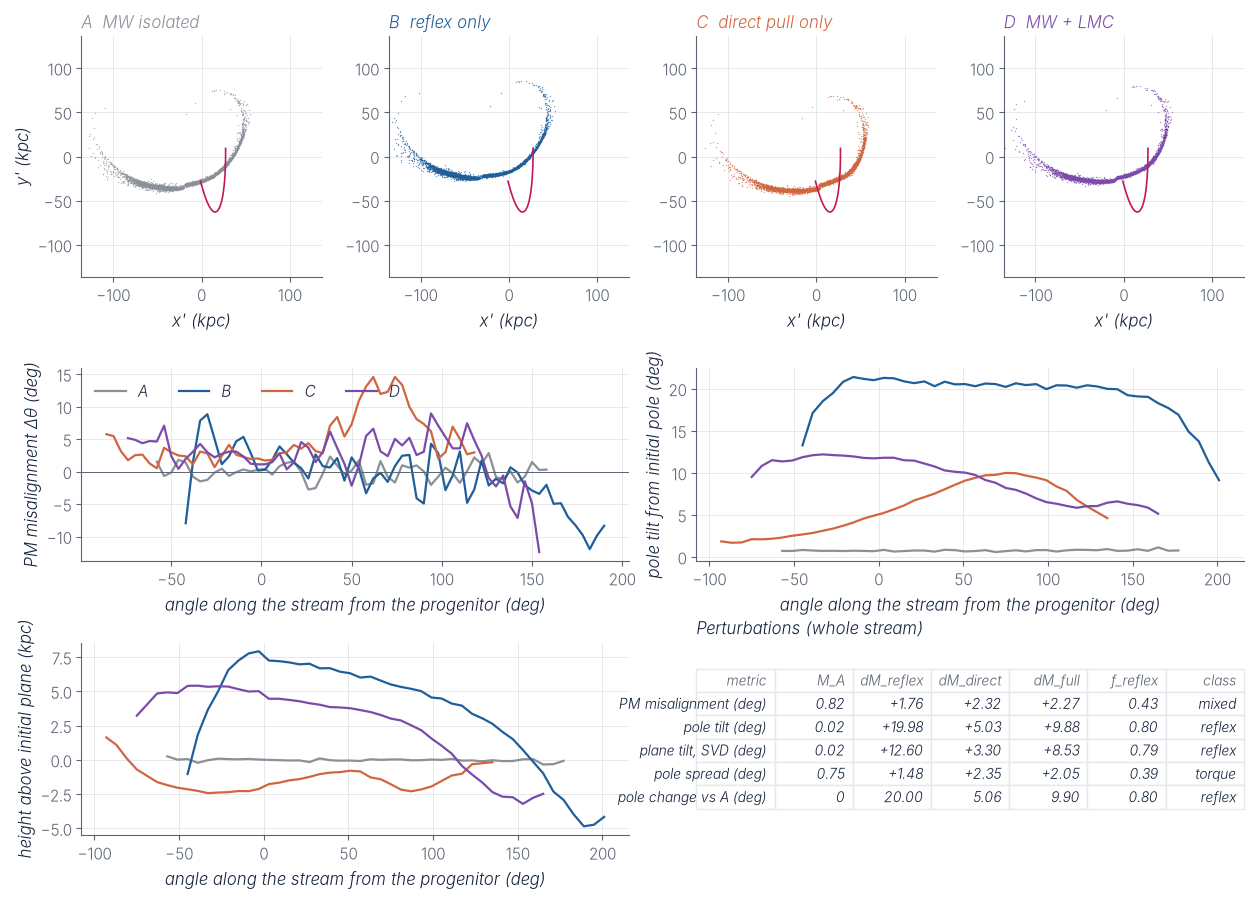

Figura: hito3_figura_unica.png 
Milestone 3. Top: the milestone-1 stream today in the four models (A isolated MW, B reflex only, C direct LMC pull only, D full MW + LMC), face-on in the initial orbital plane; magenta: LMC orbit over the last 1.5 Gyr. Middle and bottom: the three metrics along the stream (angle from the progenitor in the plane of the mean pole; leading arm > 0): proper-motion misalignment seen from the Sun, tilt of the stars' orbital poles from the initial pole, and height above the initial orbital plane. Table: perturbations relative to model A and reflex fraction f_reflex = |dM_reflex| / (|dM_reflex| + |dM_direct|).


In [4]:
fig, ax_tabla = F.hito3(CORR, PERF, N0, x0, sis)
F.tabla_en_eje(ax_tabla, tabla(RES), COLS, titulo="Perturbations (whole stream)")
PIE = "Milestone 3. Top: the milestone-1 stream today in the four models (A isolated MW, B reflex only, C direct LMC pull only, D full MW + LMC), face-on in the initial orbital plane; magenta: LMC orbit over the last 1.5 Gyr. Middle and bottom: the three metrics along the stream (angle from the progenitor in the plane of the mean pole; leading arm > 0): proper-motion misalignment seen from the Sun, tilt of the stars' orbital poles from the initial pole, and height above the initial orbital plane. Table: perturbations relative to model A and reflex fraction f_reflex = |dM_reflex| / (|dM_reflex| + |dM_direct|)."
E.guardar(fig, os.path.join(SAL, 'hito3_figura_unica.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito3_figura_unica.png', "\n" + PIE)

### Corrientes corta, larga y de dos vueltas

Las tres familias del catálogo (notebook 04), con el mismo polo $-\hat{\mathbf y}$ y $t_{\rm start} = 5$ Gyr:

| familia | $r_{\rm apo}$ | $M_{\rm prog}$ | longitud en la MW aislada |
|---|---|---|---|
| corta | 100 kpc | $10^7\,M_\odot$ | ~0.3 vueltas |
| larga | 60 kpc | $5\times10^7\,M_\odot$ | ~1.1 vueltas |
| doble | 40 kpc | $10^8\,M_\odot$ | ~1.7 vueltas |

In [5]:
REPR = {}
for fam in ("corta", "larga", "doble"):
    p = Ca.FAMILIAS[fam]
    t0 = time.time()
    REPR[fam] = cuatro(N0, p["r_apo"], p["m_prog"], C.T_START)
    print("%s: %.2f vueltas en A, %.0f s" % (fam, REPR[fam][2]["A"]["longitud_vueltas"], time.time() - t0))

corta: 0.30 vueltas en A, 19 s


larga: 1.14 vueltas en A, 35 s


doble: 1.72 vueltas en A, 56 s


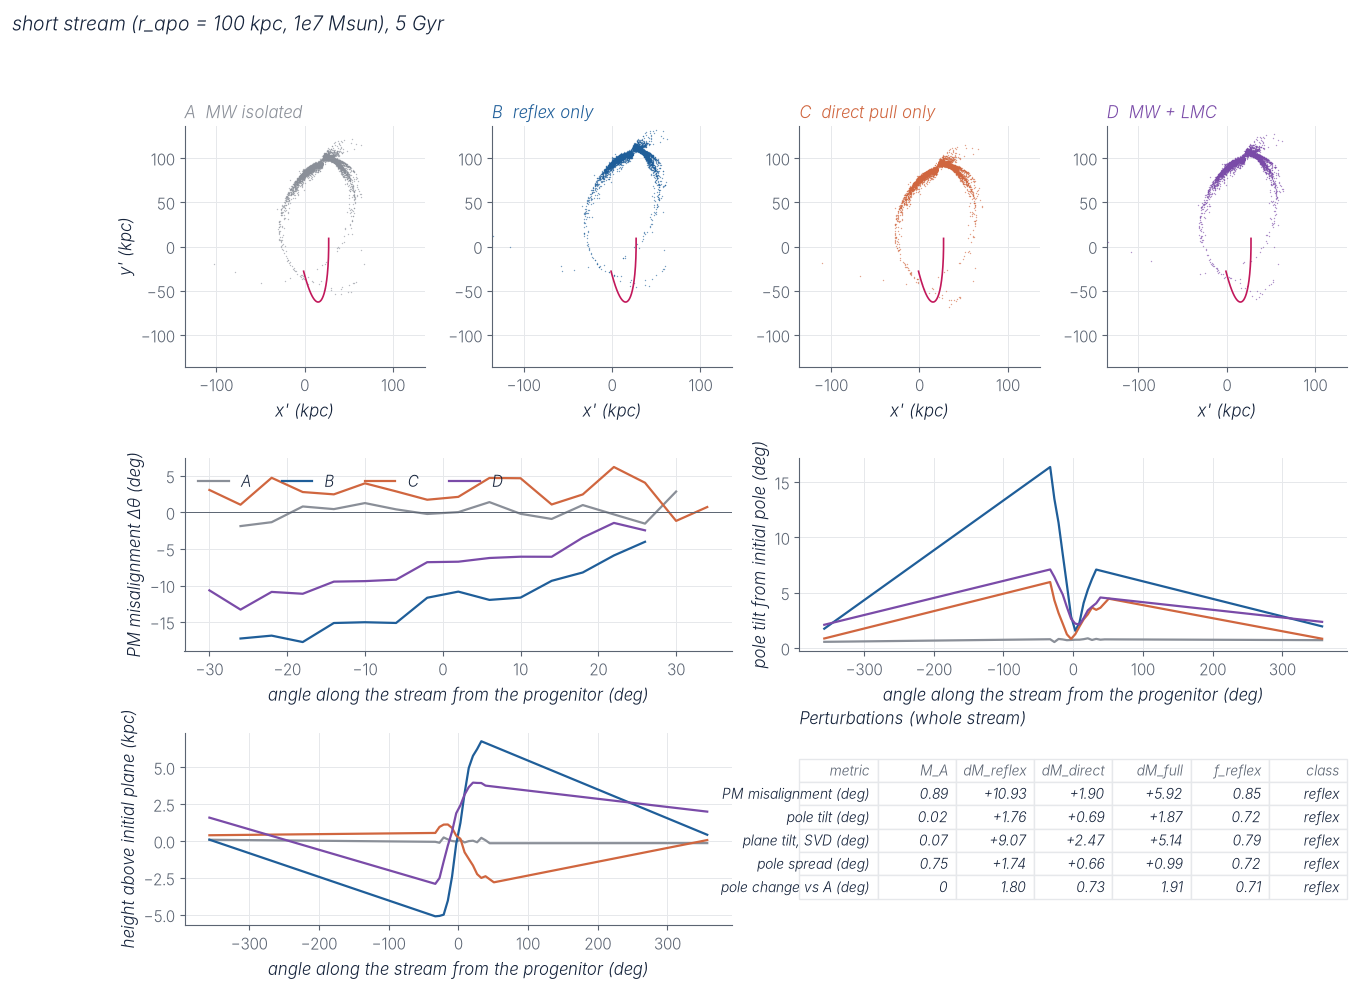

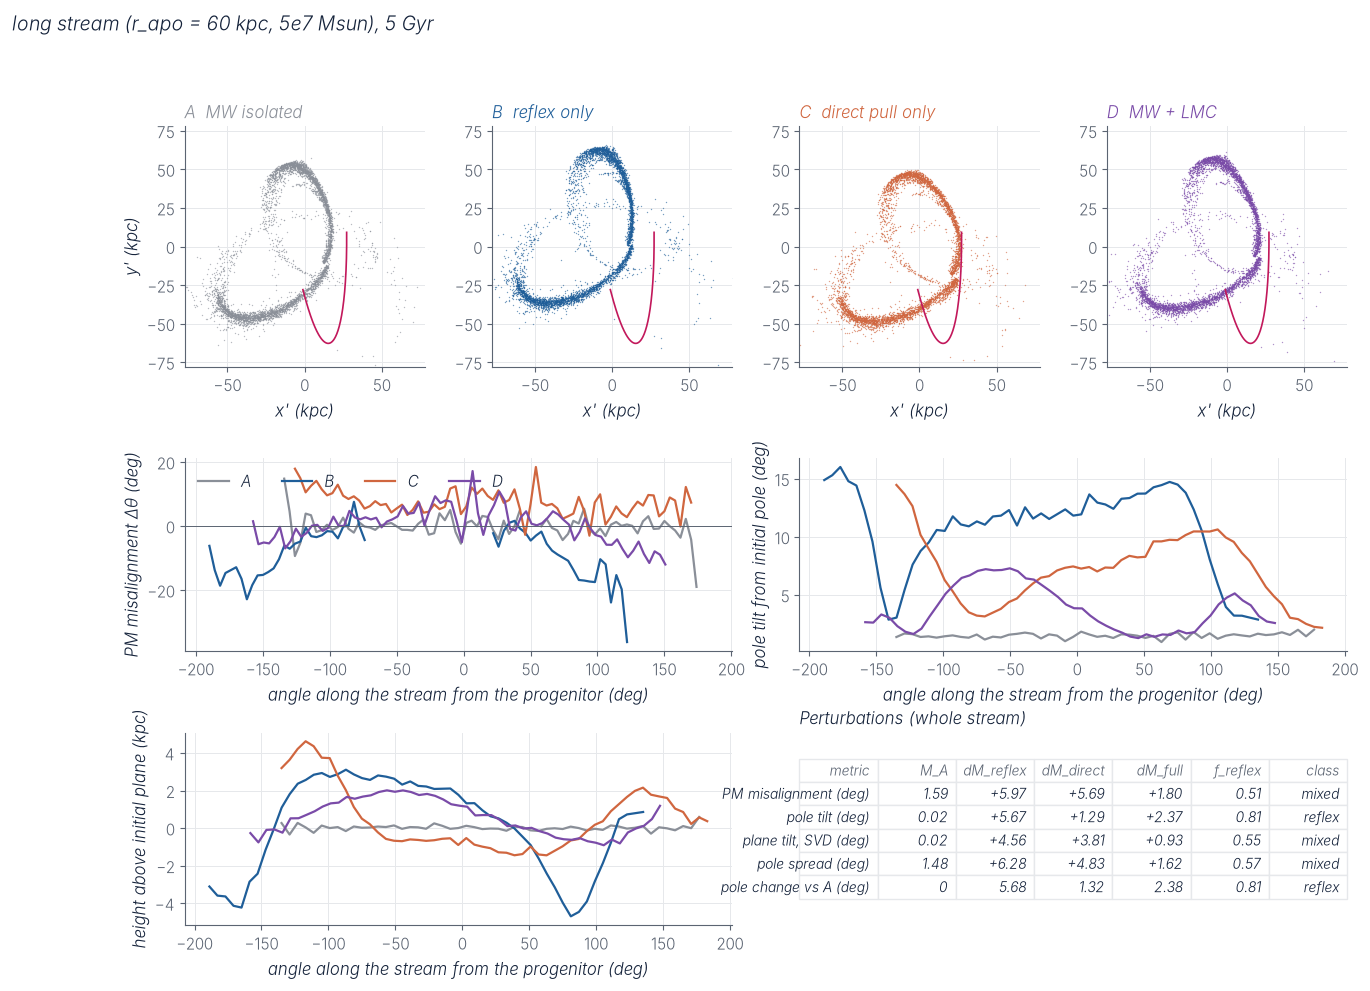

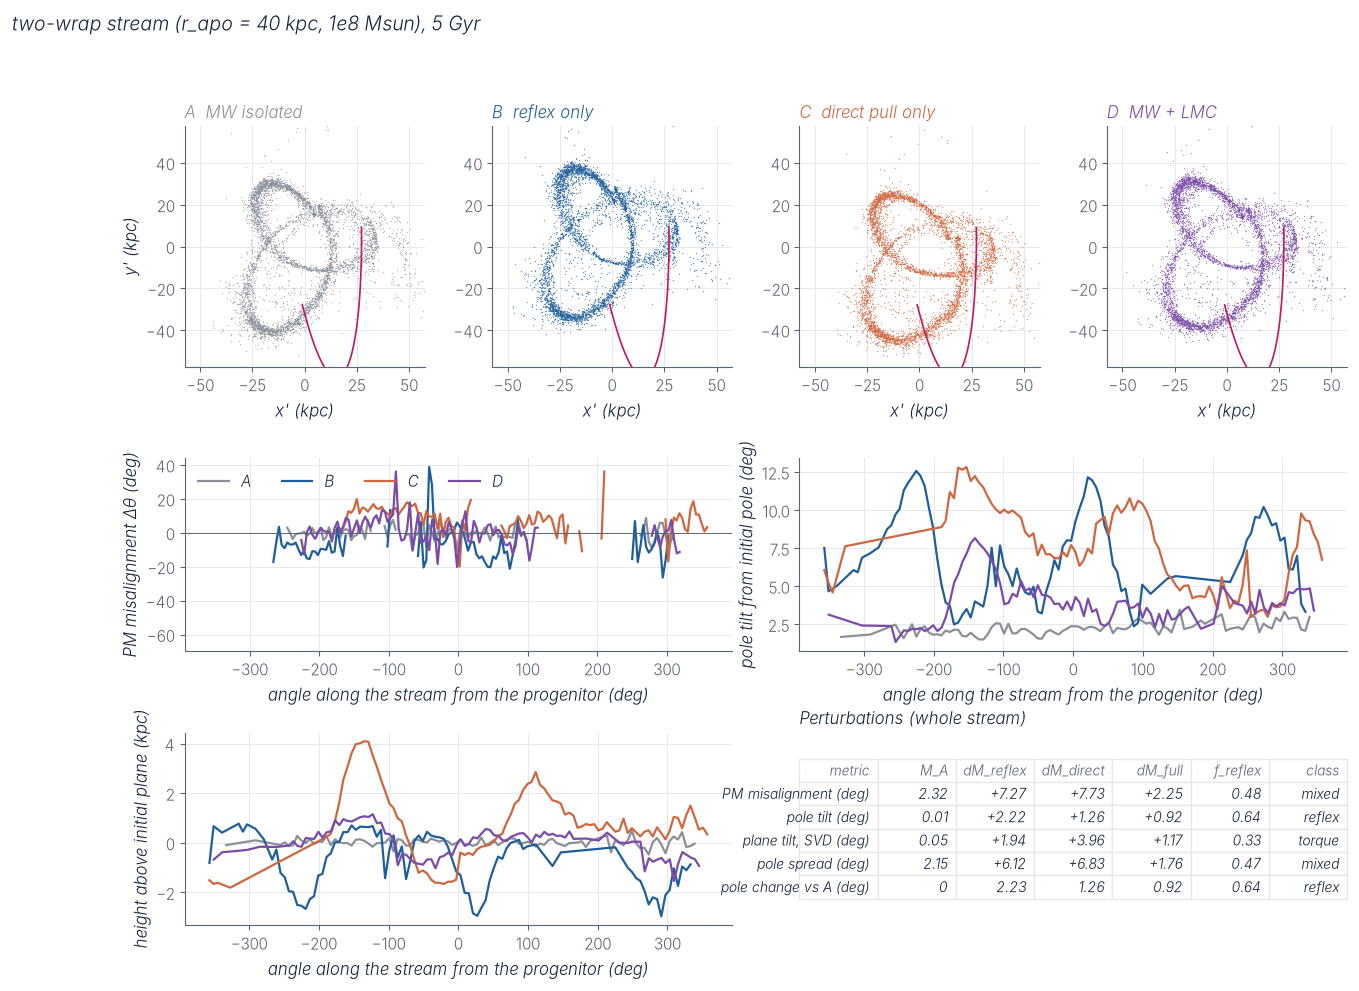

In [6]:
NOMBRE = {"corta": "short stream (r_apo = 100 kpc, 1e7 Msun)", "larga": "long stream (r_apo = 60 kpc, 5e7 Msun)",
          "doble": "two-wrap stream (r_apo = 40 kpc, 1e8 Msun)"}
for fam, (x0f, cf, rf, pf) in REPR.items():
    fig, axt = F.hito3(cf, pf, N0, x0f, sis, titulo=NOMBRE[fam] + ", 5 Gyr")
    F.tabla_en_eje(axt, tabla(rf), COLS, titulo="Perturbations (whole stream)")
    E.guardar(fig, os.path.join(SAL, "hito3_%s.png" % fam), "Stream and metrics in the four models: " + NOMBRE[fam]
              + ", initial pole -y, t_start = 5 Gyr. Panels as in the milestone-3 figure.", FUENTE, pdf=True)
    plt.show()

### Viejo contra joven

La corriente de dos vueltas se separa por la mediana del tiempo de liberación: la parte **vieja** (liberada
antes) y la **joven**.

In [7]:
filas = []
for fam, (x0f, cf, rf, pf) in REPR.items():
    for parte in ("vieja", "joven", "lider", "cola"):
        for met in ("tilt_polo_deg", "desalineamiento_deg"):
            p = Me.perturbaciones(rf, met, parte)
            filas.append(dict(familia=fam, parte=parte, metrica=met, M_A=rf["A"][parte][met],
                              dM_reflex=p["dM_reflex"], dM_direct=p["dM_direct"], dM_full=p["dM_full"],
                              f_reflex=p["f_reflex"]))
PARTES = pd.DataFrame(filas).round(2)
PARTES.to_csv(os.path.join(SAL, "hito3_partes.csv"), index=False)
PARTES

,familia,parte,metrica,M_A,dM_reflex,dM_direct,dM_full,f_reflex
0,corta,vieja,tilt_polo_deg,0.04,1.74,0.72,1.53,0.71
1,corta,vieja,desalineamiento_deg,0.92,11.75,2.13,6.92,0.85
2,corta,joven,tilt_polo_deg,0.01,1.87,0.68,2.23,0.73
3,corta,joven,desalineamiento_deg,0.36,9.52,2.51,5.29,0.79
4,corta,lider,tilt_polo_deg,0.02,1.45,1.93,1.73,0.43
5,corta,lider,desalineamiento_deg,1.01,8.35,1.82,5.05,0.82
6,corta,cola,tilt_polo_deg,0.02,4.56,1.01,3.13,0.82
7,corta,cola,desalineamiento_deg,0.82,14.31,2.02,9.25,0.88
8,larga,vieja,tilt_polo_deg,0.05,4.03,2.44,1.47,0.62
9,larga,vieja,desalineamiento_deg,2.85,12.84,4.97,1.98,0.72


## Qué muestra el hito 3

- En la corriente del hito 1, el reflejo solo inclina el polo medio ~20°, el tirón solo ~5° y el sistema completo
  ~10° [comprobado, tabla de arriba]: los dos efectos se oponen en parte, como dice el enunciado (~20° contra ~10°).
  Por el cambio del polo es una corriente dominada por el reflejo ($f_{\rm reflex}$ ≈ 0.8). Por el desalineamiento
  queda mixta (~0.4): **la clase depende de la métrica** [comprobado].
- En el modelo A todo es casi cero para esta órbita polar (piso ~0.02° en el polo y ~0.8° en el desalineamiento).
  En las órbitas no polares el disco hace precesar el plano y el piso crece (notebook 04).
- $\Delta M_{\rm full}$ no es $\Delta M_{\rm reflex} + \Delta M_{\rm direct}$: la respuesta no es lineal [comprobado].
- Las tres corrientes representativas y la comparación entre restos viejos y jóvenes se generalizan con el
  catálogo en los notebooks 04 y 05.